# Assignment 2

## Importing libraries
- All library imports are in below cell

In [58]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import random

## Data

### Load the dataset

In [2]:
  
# fetch dataset 
communities_and_crime = fetch_ucirepo(id=183) 
  
# data (as pandas dataframes) 
X = communities_and_crime.data.features 
y = communities_and_crime.data.targets 
  
# metadata 
print(communities_and_crime.metadata) 
  
# variable information 
print(communities_and_crime.variables) 

print(type(y))
print(y.columns)

{'uci_id': 183, 'name': 'Communities and Crime', 'repository_url': 'https://archive.ics.uci.edu/dataset/183/communities+and+crime', 'data_url': 'https://archive.ics.uci.edu/static/public/183/data.csv', 'abstract': 'Communities within the United States. The data combines socio-economic data from the 1990 US Census, law enforcement data from the 1990 US LEMAS survey, and crime data from the 1995 FBI UCR.', 'area': 'Social Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1994, 'num_features': 127, 'feature_types': ['Real'], 'demographics': ['Race', 'Age', 'Income', 'Occupation'], 'target_col': ['ViolentCrimesPerPop'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2002, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C53W3X', 'creators': ['Michael Redmond'], 'intro_paper': {'ID': 405, 'type': 'NATIVE', 'title': 'A data-driven software tool for enabling cooperative information s

### Prepare the dataset
- categorical data - remove or convert them to one hot encoding
- missing data

In [37]:

# removing categorical ones
# todo - convert to one hot encoding later just to try
set(X.dtypes.values)

X = X.select_dtypes(['float64','int64'])

# todo - check missing data how much NAs
before = X.shape[0]
X = X.dropna()
after = X.shape[0]

print(f"Before: {before}")
print(f"After dropping NA: {after}")

Before: 1994
After dropping NA: 1994


### Split the dataset into training and test

In [39]:
SPLIT = 0.8

split_index = int(SPLIT * X.shape[0])
train_X = X.iloc[:split_index]
train_y = y.iloc[:split_index]

test_X = X.iloc[split_index:]
test_y = y.iloc[split_index:]

## Fitting function

In [22]:
def fit_lr(train_X, train_y):
    model = LinearRegression()
    model.fit(train_X.to_numpy(), train_y.to_numpy())
    return model

def eval_mse(model, test_X, test_y):
    real_y = test_y.to_numpy()
    pred_y = model.predict(test_X.to_numpy())
    mse = np.mean((real_y - pred_y) ** 2)

    return mse

## Cross-validation method
- and also leave-one-out method, which is just a special case of cross-validation

In [25]:

# default value for k=5
def cross_validation(X, y, fit, eval, k=5):
    # todo
    # X - attributes
    # y - target variable
    # fit - fitting function
    # eval - loss evaluation function
    # k - number of bins

    row_cnt = X.shape[0]
    bin_size = row_cnt // k
    
    attr_bins = [None for _ in range(k)]
    target_bins = [None for _ in range(k)]
    # print(f'Row cnt == {row_cnt}')
    for i in range(k-1):
        # print(f'Indexing [{(bin_size * i)}:{(bin_size * (i+1))}]')
        attr_bins[i] = X.iloc[(bin_size * i):(bin_size * (i+1))]
        target_bins[i] = y.iloc[(bin_size * i):(bin_size * (i+1))]

    # filling last bin with remaining elements
    attr_bins[k-1] = X.iloc[(bin_size * (k-1)):]
    target_bins[k-1] = y.iloc[(bin_size * (k-1)):]

    loss = 0
    for i in range(k):
        val_attr_bin = attr_bins[i]
        val_target_bin = target_bins[i]

        train_attr = pd.concat([bin for j, bin in enumerate(attr_bins) if j != i], axis=0)
        train_target = pd.concat([bin for j, bin in enumerate(target_bins) if j != i], axis=0)
        model = fit(train_attr, train_target)

        loss += eval(model, val_attr_bin, val_target_bin)

    loss = loss / k
    return loss

def leave_one_out(X, y, fit, eval):
    cross_validation(X, y, fit, eval, k=X.shape[0])

In [40]:
# - test above on the loaded dataset stored in
# train_X
# train_y

cv = dict()
cv[5] = cross_validation(train_X, train_y, fit_lr, eval_mse, k=5)
cv[10] = cross_validation(train_X, train_y, fit_lr, eval_mse, k=10)
cv[20] = cross_validation(train_X, train_y, fit_lr, eval_mse, k=20)

cv['n'] = leave_one_out(train_X, train_y, fit_lr, eval_mse)

for k, mse in cv.items():
    print(f'Cross validation with {k} folds mse value:\t{mse}')


Cross validation with 5 folds mse value:	0.019414171707382633
Cross validation with 10 folds mse value:	0.019203207299628114
Cross validation with 20 folds mse value:	0.019030008560949493
Cross validation with n folds mse value:	None


## Forward attribute selection
- start with empty set of attributes
- select attribute yielding best MSE value
- add it to set
- repeat fitting, but now using the set of already added attributes + one new attribute
- select the attribute which together with the other attributes in the set decreases MSE
- two stop conditions - when either is true stop
    - when MSE increases when an attribute is added - other than the 1st one (since MSE is 0 before any fitting)
    - up to `n` attributes

In [51]:

def forward_attribute_selection(X, y, fit, eval, n=None):
    if n is None:
        n = X.shape[1]

    # todo
    best_mse = float('inf')
    selected_attrs = []
    unselected_attrs = list(X.columns)
    improve = True
    while improve:
        improve = False
        best_unselected_attr = None

        for col in unselected_attrs:
            
            selected_X = X[selected_attrs + [col]]
            mse = cross_validation(selected_X, y, fit, eval)
            if mse < best_mse:
                best_mse = mse
                best_unselected_attr = col
                improve = True

        # if no attribute decreased mse
        if not improve:
            break
        
        unselected_attrs.remove(best_unselected_attr)
        selected_attrs.append(best_unselected_attr)

        # if limited to n attributes
        if len(selected_attrs) == n:
            break
        
    return selected_attrs

## Fitting a model using forward attribute selection

In [53]:
# - call above function using only train set

selected_attributes = forward_attribute_selection(train_X, train_y, fit_lr, eval_mse)
selected_train_X = train_X[selected_attributes]
selected_test_X = test_X[selected_attributes]
model = fit_lr(selected_train_X, train_y)

print("Selected attributes:")
print(selected_attributes)

Selected attributes:
['PctKids2Par', 'racePctWhite', 'HousVacant', 'state', 'PctWorkMom', 'PctEmploy', 'NumStreet', 'agePct12t29', 'population', 'PctVacantBoarded', 'PctIlleg', 'PctPersDenseHous', 'racepctblack', 'PctHousLess3BR', 'MedOwnCostPctIncNoMtg', 'MedRentPctHousInc', 'indianPerCap', 'pctWInvInc', 'agePct16t24', 'pctUrban', 'MalePctDivorce', 'TotalPctDiv', 'pctWRetire', 'pctWWage', 'fold', 'AsianPerCap', 'PctLess9thGrade', 'PctVacMore6Mos', 'PctPopUnderPov', 'RentLowQ', 'MedRent', 'RentHighQ', 'PctPersOwnOccup', 'OwnOccLowQuart', 'MalePctNevMarr', 'PctHousNoPhone', 'PctUsePubTrans', 'agePct12t21', 'PctLargHouseOccup', 'PctSameCity85', 'PctHousOwnOcc', 'NumIlleg', 'PersPerOwnOccHous', 'PersPerRentOccHous', 'pctWFarmSelf', 'NumInShelters', 'MedYrHousBuilt', 'PersPerOccupHous']


## Testing
- testing the above generated model on test set (NOT USED IN TRAINING)

In [54]:

test_mse = eval_mse(model, selected_test_X, test_y)
print(f"Test set MSE: {test_mse:.3f}")

Test set MSE: 0.018


## Bootstrap
- Implement the bootstrap method

In [56]:
random.seed()
def bootstrap(X, y, size=None):
    """
    size - size of the bootstraped set, by default the same size as input
    """
    if size is None:
        n = X.shape[0]
    else:
        n = size


    
    indexes = random.choices([i for i in range(X.shape[0])], k=n)
    sampled_X = X.iloc[indexes]
    sampled_y = y.iloc[indexes]
    return sampled_X, sampled_y

### Confidence intervals
- apply it to the train set to generate 1000 different train sets and train 1000 different linear models
- **Use only the attributes you selected with forward feature selection**
- Use the bootstrapped results to assess the confidence intervals of MSE of the linear
model on your independent test set

In [57]:
# call above method to generate 1000 diff train sets and 1000 diff models
# ? save the mse of each

number_of_bootstraps = 1000

mse_bootstrap = []
for i in range(number_of_bootstraps):
    bst_X, bst_y = bootstrap(selected_train_X, train_y)
    model = fit_lr(bst_X, bst_y)
    mse = eval_mse(model, selected_test_X, test_y)

    mse_bootstrap.append(mse)

mse_bootstrap.sort()

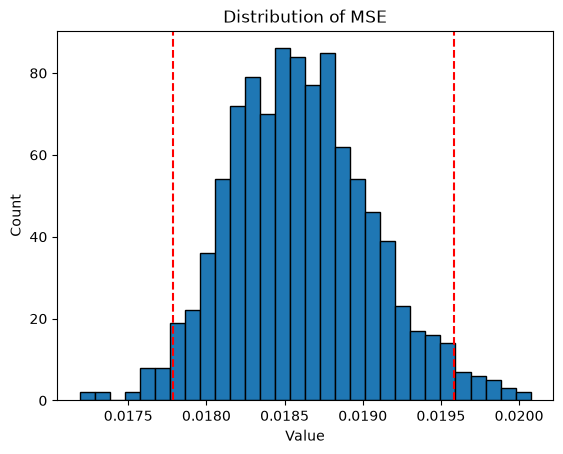

In [61]:
# todo - plot mse bootstrap distribution
lower, upper = np.percentile(mse_bootstrap, [2.5, 97.5])
plt.hist(mse_bootstrap, bins=30, edgecolor="black")
plt.axvline(lower, color="red", linestyle="--", label=f"2.5th percentile ({lower:.2f})")
plt.axvline(upper, color="red", linestyle="--", label=f"97.5th percentile ({upper:.2f})")
plt.title("Distribution of MSE")
plt.xlabel("Value")
plt.ylabel("Count")
plt.show()

In [63]:
print(f"95% confidence interval is between {lower:.3f} and {upper:.3f}")

95% confidence interval is between 0.018 and 0.020
